## Regularization

In [3]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from utils import SIZE, CLASSES, prepare_data_set, plot_costs, load_image, get_label
from dnn import (
    relu, sigmoid, initialize_parameters, activate,
    ActivationCache, PropagateCache, ForwardCache,
    propagate, propagate_backward,
    AL_derivative, relu_backward, sigmoid_backward,
)

In [4]:
datasets = prepare_data_set()

Y_train = datasets["Y_train"]
X_train = datasets ["X_train"]
X_test = datasets["X_test"]
Y_test = datasets["Y_test"]
X_test_orig_set = datasets["X_test_orig_set"]
X_train_orig_set = datasets["X_train_orig_set"]

In [5]:
def forward_pass(X, parameters):
    # find the number of layers from the initialized parameters
    L = len(parameters) // 2

    # print(f"Len Layer: {L}")
    cache = [] # we need this later for backward propagation
    Aprev = X # initial assignment to A0
    for l in range(0,L):
        # here we calculate Zl     
        Zl, pc = propagate(parameters["W"+str(l+1)], Aprev, parameters["b"+str(l+1)])
        # here we calculate Al (it should be started from 1 by the loop)
        if (l == (L-1)): # for output layer, we use sigmoid
            Aprev, ac= activate(Zl, "sigmoid")
        else:
            Aprev, ac= activate(Zl, "relu")
        forward_cache = ForwardCache(PropagateCache = pc, ActivationCache=ac) 
        cache.append(forward_cache)
    output = Aprev
    # print(f"Len in forward: {len(cache)} {len(parameters)} ")
    return output, cache

In [6]:
def backward_pass(AL, Y, caches):

    grads = {}
    L = len(caches)
    current_layer_cache = caches[L-1]
    current_layer_W = current_layer_cache.PropagateCache.W
    current_layer_Aprev = current_layer_cache.PropagateCache.Aprev
    
    # get the dZ for outer/output layer
    # sigmoid + binary cross-entropy simplifies to dZ = AL - Y
    dZ = AL-Y
    dW,db, dAprev = propagate_backward(dZ, current_layer_Aprev, current_layer_W )
    grads["dW"+str(L)] = dW
    grads["db"+str(L)] = db

    # print(f"l in backward = {L}")
    
    for l in reversed (range (L-1)):
        current_layer_cache = caches[l]
        current_layer_W = current_layer_cache.PropagateCache.W
        current_layer_Aprev = current_layer_cache.PropagateCache.Aprev
        dZ = relu_backward(dAprev, current_layer_cache.ActivationCache)
        dW,db,dAprev = propagate_backward(dZ, current_layer_Aprev, current_layer_W)
        # print(f"l in backward = {l+1}")
        grads["dW" + str(l+1)] = dW
        grads["db" + str(l+1)] = db
    
    return grads

In [7]:
def calculate_cost(AL,Y):
    m = AL.shape[1]
    # clip AL to avoid log(0).
    AL = np.clip(AL, 1e-8, 1 - 1e-8)
    cost =  -(1./m) * np.sum((np.dot(Y,np.log(AL).T) + np.dot(1-Y, np.log(1-AL).T)))
    # make sure the output not a 0-dimensional array/scalar
    # eg 2D array (matrix) number: [[24]] => become 24.
    res = np.squeeze(cost)
    return res

In [8]:
def update_parameter(parameters, grads, learning_rate):

    # floor divide by 2 because each layer has both a 'W' and a 'b'
    L = len(parameters) // 2
    
    for l in range (0, L):
        parameters["W" + str(l+1)] = parameters["W" + str(l+1)] - (learning_rate * grads["dW"+str(l+1)])
        parameters["b" + str(l+1)] = parameters["b" + str(l+1)] - (learning_rate * grads["db"+str(l+1)])

    assert len(grads) == len(parameters)
    return parameters

In [9]:
def classify(X,parameters):
    output, _ = forward_pass(X,parameters)
    return (output > 0.5).astype(int)


def random_mini_batches(X, Y, mini_batch_size=64, seed=3):
    np.random.seed(seed)
    m = X.shape[1]
    total_batches =  m // mini_batch_size

    permutation = list(np.random.permutation(m))
    shuffled_X = X[:, permutation]
    shuffled_Y = Y[:, permutation].reshape((1,m))
    
    mini_batches = []
    for k in range (0, total_batches):
        i = k * mini_batch_size
        j = (k+1) * mini_batch_size
        mini_X = shuffled_X[:, i:j]
        mini_Y = shuffled_Y[:, i:j]
        mini_batch = (mini_X, mini_Y)
        mini_batches.append(mini_batch)
    if m % mini_batch_size != 0:
        i = total_batches * mini_batch_size
        mini_X = shuffled_X[:, i:]
        mini_Y = shuffled_Y[:, i:]
        mini_batch = (mini_X, mini_Y)
        mini_batches.append(mini_batch)


    return mini_batches

In [10]:
def initialize_velocity(parameters):
    L = len(parameters)//2
    v = {}

    for l in range (1, L+1):
        W = parameters["W" + str(l)]
        b = parameters ["b"+ str(l)]

        v["dW" + str(l)] = np.zeros(W.shape)
        v["db" + str(l)] = np.zeros(b.shape)

    return v

def update_parameter_with_momentum(parameters, grads, v,beta, learning_rate):

    L = len(parameters)//2

    for l in range (1, L+1):
        v["dW"+str(l)] = beta * v["dW"+str(l)] + (1 - beta) * grads["dW"+str(l)]
        v["db"+str(l)] = beta * v["db"+str(l)] + (1 - beta) * grads["db"+str(l)]

        parameters["W"+str(l)] = parameters["W"+str(l)] - learning_rate * v["dW"+str(l)]
        parameters["b"+str(l)] = parameters["b"+str(l)] - learning_rate * v["db"+str(l)]

    return parameters, v

In [11]:
def initialize_squared_prop(parameters):
    L = len(parameters)//2
    s = {}

    for l in range (1, L+1):
        W = parameters["W" + str(l)]
        b = parameters ["b"+ str(l)]

        s["dW" + str(l)] = np.zeros(W.shape)
        s["db" + str(l)] = np.zeros(b.shape)

    return s

def update_parameter_with_rmsprop(parameters, grads, s,beta, epsilon, learning_rate):

    L = len(parameters)//2

    for l in range (1, L+1):
        s["dW"+str(l)] = beta * s["dW"+str(l)] + (1 - beta) * np.power(grads["dW"+str(l)],2)
        s["db"+str(l)] = beta * s["db"+str(l)] + (1 - beta) * np.power(grads["db"+str(l)],2)

        parameters["W"+str(l)] = parameters["W"+str(l)] - learning_rate * (grads["dW"+str(l)] /  (np.sqrt(s["dW"+str(l)]) + epsilon))
        parameters["b"+str(l)] = parameters["b"+str(l)] - learning_rate * (grads["db"+str(l)] /  (np.sqrt(s["db"+str(l)]) + epsilon))

    return parameters, s

In [12]:
def initialize_adam(parameters):
    L = len(parameters)//2
    s = {}
    v = {}

    for l in range (1, L+1):
        W = parameters["W" + str(l)]
        b = parameters ["b"+ str(l)]

        s["dW" + str(l)] = np.zeros(W.shape)
        s["db" + str(l)] = np.zeros(b.shape)
        v["dW" + str(l)] = np.zeros(W.shape)
        v["db" + str(l)] = np.zeros(b.shape)

    return s,v

def update_parameter_with_adam(parameters, grads, s, v, beta1, beta2, epsilon, t, learning_rate):

    L = len(parameters)//2
    s_corrected = {}
    v_corrected = {}
    for l in range (1, L+1):
        v["dW"+str(l)] = beta1 * v["dW"+str(l)] + (1 - beta1) * grads["dW"+str(l)]
        v["db"+str(l)] = beta1 * v["db"+str(l)] + (1 - beta1) * grads["db"+str(l)]
        
        s["dW"+str(l)] = beta2 * s["dW"+str(l)] + (1 - beta2) * np.power(grads["dW"+str(l)],2)
        s["db"+str(l)] = beta2 * s["db"+str(l)] + (1 - beta2) * np.power(grads["db"+str(l)],2)
        

        v_corrected["dW"+str(l)] = v["dW"+str(l)] / (1 - np.power(beta1,t))
        v_corrected["db"+str(l)] = v["db"+str(l)] / (1 - np.power(beta1,t))
        
        s_corrected["dW"+str(l)] = s["dW"+str(l)] / (1 - np.power(beta2, t))
        s_corrected["db"+str(l)] = s["db"+str(l)] / (1 - np.power(beta2, t))

        parameters["W"+str(l)] = parameters["W"+str(l)] - learning_rate * (v_corrected["dW"+str(l)] /  (np.sqrt(s_corrected["dW"+str(l)]) + epsilon))
        parameters["b"+str(l)] = parameters["b"+str(l)] - learning_rate * (v_corrected["db"+str(l)] /  (np.sqrt(s_corrected["db"+str(l)]) + epsilon))

    return parameters, s, v, s_corrected, v_corrected

In [13]:
def calculate_cost_L2(AL,Y, parameters, lambd, m):
    cost = calculate_cost(AL,Y)
    L = len(parameters)//2
    Wl = []
    for l in range(1,L+1):
        W = np.sum(np.square(parameters["W"+str(l)]))
        Wl.append(W)

    L2_regularization_cost = (lambd / (2 * m)) * np.sum(Wl)
    cost = cost + L2_regularization_cost
    return cost

def backward_pass_L2(AL, Y, caches, lambd, m):
    grads = backward_pass(AL,Y, caches)
    L = len(caches)
    for l in reversed (range (0, L)):
        cc = caches[l].PropagateCache
        grads["dW"+str(l+1)] = grads["dW"+str(l+1)] + ((lambd / m) * cc.W)
        
    return grads

In [14]:
# optimizer: "plain", "momentum", "rmsprop" or "adam"
# beta is used by momentum and rmsprop, beta1/beta2 by adam, epsilon by rmsprop and adam
def dnn_model_mini_batch(X_train, Y_train, X_test, Y_test, layers_dims, iteration=2500, 
              learning_rate=0.0075, mini_batch_size=64, seed = 3, optimizer="plain",
              beta=0.9, beta1=0.9, beta2=0.999, epsilon=1e-8, lambd=0.01, print_cost=False):
    
    parameters = initialize_parameters(layers_dims)
    match optimizer:
        case "plain":
            pass
        case "momentum":
            v = initialize_velocity(parameters)
        case "rmsprop":
            s = initialize_squared_prop(parameters)
        case "adam":
            s,v = initialize_adam(parameters)
        case _:
            raise ValueError(f"unknown optimizer {optimizer!r}, use plain, momentum, rmsprop or adam")

    epoch_costs = []
    batch_costs = []
    t = 0
    m_total = X_train.shape[1]
    for i in range(1,iteration+1):
        mini_batches = random_mini_batches(X_train, Y_train, mini_batch_size, seed+i)
        num_batches = len(mini_batches)
        this_epoch_costs = []
        for k in range (0, num_batches):
            X, Y = mini_batches[k]
            AL, cache = forward_pass(X, parameters)
            cost = calculate_cost_L2(AL,Y, parameters, lambd, m_total)
            grads = backward_pass_L2(AL, Y, cache, lambd, m_total)
            this_epoch_costs.append(cost)
            batch_costs.append(cost)
            match optimizer:
                case "plain":
                    parameters = update_parameter(parameters, grads, learning_rate)
                case "momentum":
                    parameters,v = update_parameter_with_momentum(parameters, grads, v, beta, learning_rate)
                case "rmsprop":
                    parameters,s = update_parameter_with_rmsprop(parameters, grads, s, beta, epsilon, learning_rate)
                case "adam":
                    t = t + 1
                    parameters,s,v,_,_ = update_parameter_with_adam(parameters, grads, s,v, beta1, beta2, epsilon, t, learning_rate)
        
        cost_avg = np.average(this_epoch_costs)
        epoch_costs.append(cost_avg)
        if (i%100 == 0) and print_cost:
            print(f"Cost: {cost_avg}")
    
    
    Y_prediction_train = classify(X_train, parameters)
    Y_prediction_test  = classify(X_test, parameters)

    train_acc = 100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100
    test_acc = 100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100
    print(f"train_accuracy: {train_acc}%")
    print(f"test_accuracy: {test_acc}%")

    return parameters, batch_costs, epoch_costs

In [13]:
import time
start_time = time.perf_counter()
input_features = X_train.shape[0]
iteration = 900
learning_rate = 0.0001
mini_batch_size = 128
seed = 3
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
lambd = 0.01
layer_dims_deep = [input_features, 30, 20, 10, 1]
parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
        X_train=X_train,
        Y_train=Y_train,
        X_test=X_test,
        Y_test=Y_test,
        layers_dims=layer_dims_deep,
        iteration=iteration,
        learning_rate=learning_rate,
        mini_batch_size=mini_batch_size,
        seed=seed,
        optimizer="adam",
        beta1=beta1,
        beta2=beta2,
        epsilon=epsilon,
        lambd=lambd,
        print_cost=True)

elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f"Execution time: {elapsed_minutes:.2f} minutes")

Cost: 0.5392572131697144


Cost: 0.46259330665910636


Cost: 0.3926410253644603


Cost: 0.3433114717859835


Cost: 0.27831563694804246


Cost: 0.23799507426145225


Cost: 0.2456705201435397


Cost: 0.16165748146795333


Cost: 0.1294663779084174
train_accuracy: 96.83947532792006%
test_accuracy: 61.14681166584281%
Execution time: 8.20 minutes


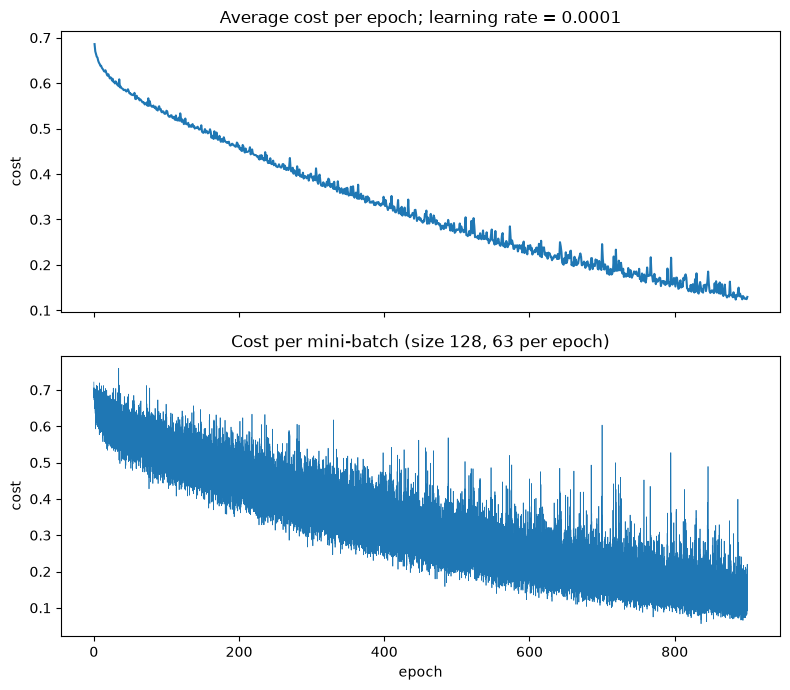

In [14]:
# epoch_costs has one point per epoch, batch_costs one point per mini-batch update.
# Put both on an epoch axis so the noise of each mini-batch lines up with its epoch.
batches_per_epoch = len(batch_costs) // len(epoch_costs)
epochs = np.arange(1, len(epoch_costs) + 1)
batch_steps = np.arange(1, len(batch_costs) + 1) / batches_per_epoch

fig, (ax_epoch, ax_batch) = plt.subplots(2, 1, sharex=True, figsize=(8, 7))

ax_epoch.plot(epochs, epoch_costs)
ax_epoch.set_title(f"Average cost per epoch; learning rate = {learning_rate}")
ax_epoch.set_ylabel("cost")

ax_batch.plot(batch_steps, batch_costs, linewidth=0.5)
ax_batch.set_title(f"Cost per mini-batch (size {mini_batch_size}, {batches_per_epoch} per epoch)")
ax_batch.set_xlabel("epoch")
ax_batch.set_ylabel("cost")

plt.tight_layout()
plt.show()

In [15]:
for lambd in (0.01, 10, 20, 40, 60, 100, 300, 1000):
      print(f"--- L2 lambd = {lambd}")
      parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
              X_train=X_train,
              Y_train=Y_train,
              X_test=X_test,
              Y_test=Y_test,
              layers_dims=layer_dims_deep,
              iteration=900,
              learning_rate=0.0001,
              mini_batch_size=128,
              seed=3,
              optimizer="adam",
              lambd=lambd)
      weights = np.concatenate([parameter_deep["W"+str(l)].ravel() for l in range(1, 5)])
      print("sum W^2:", np.sum(weights ** 2))

--- L2 lambd = 0.01


train_accuracy: 96.83947532792006%
test_accuracy: 61.14681166584281%
sum W^2: 134.5910675324884
--- L2 lambd = 10


train_accuracy: 99.92504684572143%
test_accuracy: 61.641127039050915%
sum W^2: 99.52430308112704
--- L2 lambd = 20


train_accuracy: 99.38788257339164%
test_accuracy: 62.333168561542266%
sum W^2: 85.49882140272457
--- L2 lambd = 40


train_accuracy: 99.262960649594%
test_accuracy: 61.542263964409294%
sum W^2: 51.638235684956186
--- L2 lambd = 60


train_accuracy: 99.20049968769519%
test_accuracy: 61.69055857637172%
sum W^2: 41.45782296034204
--- L2 lambd = 100


train_accuracy: 94.62835727670206%
test_accuracy: 62.58032624814632%
sum W^2: 34.16383385826445
--- L2 lambd = 300


train_accuracy: 74.3785134291068%
test_accuracy: 64.4092931290163%
sum W^2: 6.957027505251537
--- L2 lambd = 1000


train_accuracy: 50.031230480949404%
test_accuracy: 50.02471576866041%
sum W^2: 2.8576005548498274e-06


In [16]:
def calculate_cost_L1(AL, Y, parameters, lambd, m):
    cost = calculate_cost(AL,Y)
    L = len(parameters)//2
    Wl = []
    for l in range (1, L+1):
        W = np.sum(np.absolute(parameters["W"+str(l)]))
        Wl.append(W)

    L1_regularization_cost = (lambd / m) * np.sum(Wl)
    cost = cost + L1_regularization_cost
    return cost
    

def backward_pass_L1(AL, Y, caches, lambd, m):
    grads = backward_pass(AL,Y, caches)
    L = len(caches)
    for l in reversed (range (0,L)):
        cc = caches[l].PropagateCache
        grads["dW"+str(l+1)] = grads["dW"+str(l+1)] + ((lambd / m) * np.sign(cc.W))
    return grads

In [17]:
# optimizer: "plain", "momentum", "rmsprop" or "adam"
# beta is used by momentum and rmsprop, beta1/beta2 by adam, epsilon by rmsprop and adam
def dnn_model_mini_batch(X_train, Y_train, X_test, Y_test, layers_dims, iteration=2500, 
              learning_rate=0.0075, mini_batch_size=64, seed = 3, optimizer="plain",
              beta=0.9, beta1=0.9, beta2=0.999, epsilon=1e-8, lambd=0.01, regularization="L2", print_cost=False):
    
    parameters = initialize_parameters(layers_dims)
    match optimizer:
        case "plain":
            pass
        case "momentum":
            v = initialize_velocity(parameters)
        case "rmsprop":
            s = initialize_squared_prop(parameters)
        case "adam":
            s,v = initialize_adam(parameters)
        case _:
            raise ValueError(f"unknown optimizer {optimizer!r}, use plain, momentum, rmsprop or adam")

    epoch_costs = []
    batch_costs = []
    t = 0
    m_total = X_train.shape[1]
    for i in range(1,iteration+1):
        mini_batches = random_mini_batches(X_train, Y_train, mini_batch_size, seed+i)
        num_batches = len(mini_batches)
        this_epoch_costs = []
        for k in range (0, num_batches):
            X, Y = mini_batches[k]
            match regularization:
                case "L1":
                    AL, cache = forward_pass(X, parameters)
                    cost = calculate_cost_L1(AL,Y, parameters, lambd, m_total)
                    grads = backward_pass_L1(AL, Y, cache, lambd, m_total)
                case "L2":
                    AL, cache = forward_pass(X, parameters)
                    cost = calculate_cost_L2(AL,Y, parameters, lambd, m_total)
                    grads = backward_pass_L2(AL, Y, cache, lambd, m_total)
                case _:
                    raise ValueError(f"unknown regularization {regularization!r}, use L1 or L2")
            this_epoch_costs.append(cost)
            batch_costs.append(cost)
            match optimizer:
                case "plain":
                    parameters = update_parameter(parameters, grads, learning_rate)
                case "momentum":
                    parameters,v = update_parameter_with_momentum(parameters, grads, v, beta, learning_rate)
                case "rmsprop":
                    parameters,s = update_parameter_with_rmsprop(parameters, grads, s, beta, epsilon, learning_rate)
                case "adam":
                    t = t + 1
                    parameters,s,v,_,_ = update_parameter_with_adam(parameters, grads, s,v, beta1, beta2, epsilon, t, learning_rate)
        
        cost_avg = np.average(this_epoch_costs)
        epoch_costs.append(cost_avg)
        if (i%100 == 0) and print_cost:
            print(f"Cost: {cost_avg}")
    
    
    Y_prediction_train = classify(X_train, parameters)
    Y_prediction_test  = classify(X_test, parameters)

    train_acc = 100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100
    test_acc = 100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100
    print(f"train_accuracy: {train_acc}%")
    print(f"test_accuracy: {test_acc}%")

    return parameters, batch_costs, epoch_costs

In [18]:
import time
start_time = time.perf_counter()
input_features = X_train.shape[0]
iteration = 900
learning_rate = 0.0001
mini_batch_size = 128
seed = 3
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
lambd = 1
layer_dims_deep = [input_features, 30, 20, 10, 1]
parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
        X_train=X_train,
        Y_train=Y_train,
        X_test=X_test,
        Y_test=Y_test,
        layers_dims=layer_dims_deep,
        iteration=iteration,
        learning_rate=learning_rate,
        mini_batch_size=mini_batch_size,
        seed=seed,
        optimizer="adam",
        beta1=beta1,
        beta2=beta2,
        epsilon=epsilon,
        lambd=lambd,
        regularization="L1",
        print_cost=True)

elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f"Execution time: {elapsed_minutes:.2f} minutes")

Cost: 0.6152544955721234


Cost: 0.5407219688718949


Cost: 0.49402285805938684


Cost: 0.44296411611056086


Cost: 0.38322465962058905


Cost: 0.34733243721714496


Cost: 0.31075734990331644


Cost: 0.25104065866286435


Cost: 0.24944781976302616
train_accuracy: 95.11555277951281%
test_accuracy: 63.173504695996044%
Execution time: 8.52 minutes


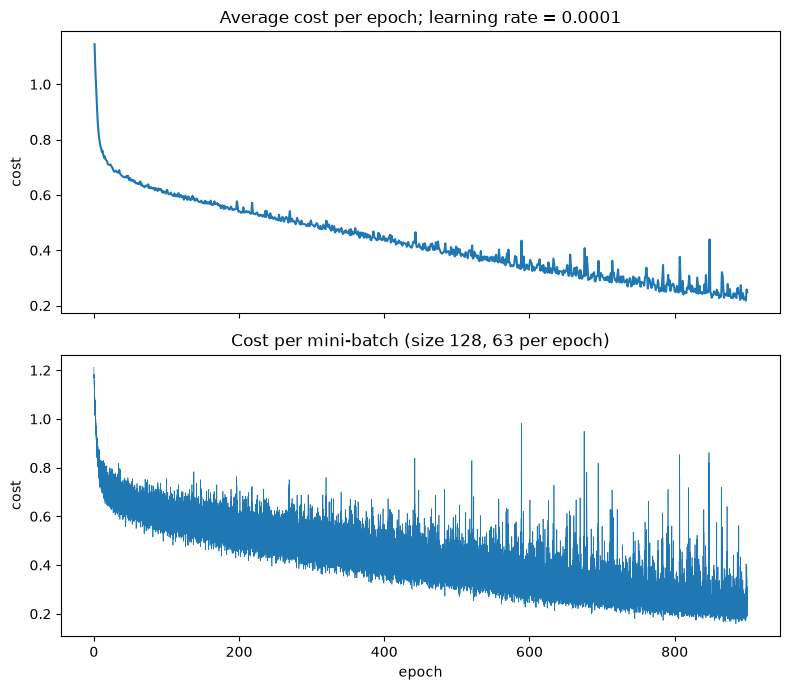

In [19]:
# epoch_costs has one point per epoch, batch_costs one point per mini-batch update.
# Put both on an epoch axis so the noise of each mini-batch lines up with its epoch.
batches_per_epoch = len(batch_costs) // len(epoch_costs)
epochs = np.arange(1, len(epoch_costs) + 1)
batch_steps = np.arange(1, len(batch_costs) + 1) / batches_per_epoch

fig, (ax_epoch, ax_batch) = plt.subplots(2, 1, sharex=True, figsize=(8, 7))

ax_epoch.plot(epochs, epoch_costs)
ax_epoch.set_title(f"Average cost per epoch; learning rate = {learning_rate}")
ax_epoch.set_ylabel("cost")

ax_batch.plot(batch_steps, batch_costs, linewidth=0.5)
ax_batch.set_title(f"Cost per mini-batch (size {mini_batch_size}, {batches_per_epoch} per epoch)")
ax_batch.set_xlabel("epoch")
ax_batch.set_ylabel("cost")

plt.tight_layout()
plt.show()

In [20]:
for lambd in (2, 4, 8, 16):
      print(f"--- L1 lambd = {lambd}")
      parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
              X_train=X_train,
              Y_train=Y_train,
              X_test=X_test,
              Y_test=Y_test,
              layers_dims=layer_dims_deep,
              iteration=900,
              learning_rate=0.0001,
              mini_batch_size=128,
              seed=3,
              optimizer="adam",
              lambd=lambd,
              regularization="L1")
      weights = np.concatenate([parameter_deep["W"+str(l)].ravel() for l in range(1, 5)])
      print("sum |W|:", np.sum(np.abs(weights)))
      print(f"near-zero weights (|W| < 1e-3): {np.mean(np.abs(weights) < 1e-3) * 100:.1f}%")

--- L1 lambd = 2


train_accuracy: 86.59587757651468%
test_accuracy: 59.07068709836876%
sum |W|: 389.04558249207037
near-zero weights (|W| < 1e-3): 92.3%
--- L1 lambd = 4


train_accuracy: 80.44971892567145%
test_accuracy: 63.074641621354424%
sum |W|: 192.67430985108322
near-zero weights (|W| < 1e-3): 96.7%
--- L1 lambd = 8


train_accuracy: 77.48906933166771%
test_accuracy: 62.135442412259025%
sum |W|: 102.87030964858218
near-zero weights (|W| < 1e-3): 98.4%
--- L1 lambd = 16


train_accuracy: 61.574016239850096%
test_accuracy: 58.180919426594166%
sum |W|: 18.75100328090403
near-zero weights (|W| < 1e-3): 99.9%


In [21]:
import time
start_time = time.perf_counter()
input_features = X_train.shape[0]
iteration = 900
learning_rate = 0.0001
mini_batch_size = 128
seed = 3
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
lambd = 10
layer_dims_deep = [input_features, 30, 20, 10, 1]
parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
        X_train=X_train,
        Y_train=Y_train,
        X_test=X_test,
        Y_test=Y_test,
        layers_dims=layer_dims_deep,
        iteration=iteration,
        learning_rate=learning_rate,
        mini_batch_size=mini_batch_size,
        seed=seed,
        optimizer="adam",
        beta1=beta1,
        beta2=beta2,
        epsilon=epsilon,
        lambd=lambd,
        regularization="L1",
        print_cost=True)

elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f"Execution time: {elapsed_minutes:.2f} minutes")

Cost: 0.7348839163656007


Cost: 0.6997541894440795


Cost: 0.6998838710368408


Cost: 0.6766094391771481


Cost: 0.6832377966123422


Cost: 0.6627964106175085


Cost: 0.6616970577566959


Cost: 0.6531671291564722


Cost: 0.6478667256032004
train_accuracy: 71.98001249219237%
test_accuracy: 62.4814631735047%
Execution time: 9.24 minutes


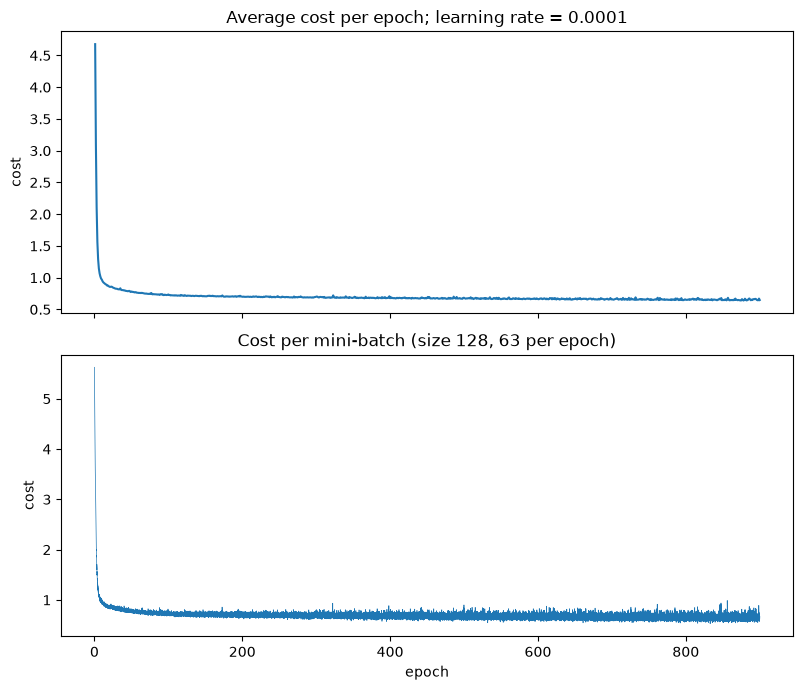

In [22]:
# epoch_costs has one point per epoch, batch_costs one point per mini-batch update.
# Put both on an epoch axis so the noise of each mini-batch lines up with its epoch.
batches_per_epoch = len(batch_costs) // len(epoch_costs)
epochs = np.arange(1, len(epoch_costs) + 1)
batch_steps = np.arange(1, len(batch_costs) + 1) / batches_per_epoch

fig, (ax_epoch, ax_batch) = plt.subplots(2, 1, sharex=True, figsize=(8, 7))

ax_epoch.plot(epochs, epoch_costs)
ax_epoch.set_title(f"Average cost per epoch; learning rate = {learning_rate}")
ax_epoch.set_ylabel("cost")

ax_batch.plot(batch_steps, batch_costs, linewidth=0.5)
ax_batch.set_title(f"Cost per mini-batch (size {mini_batch_size}, {batches_per_epoch} per epoch)")
ax_batch.set_xlabel("epoch")
ax_batch.set_ylabel("cost")

plt.tight_layout()
plt.show()

In [15]:
def forward_pass_with_dropout(X, parameters, keep_prob=1):
    # keep_prob = 0 would drop every neuron and then divide by 0, so reject it.
    if not (0 < keep_prob <= 1):
        raise ValueError(f"keep_prob must be in (0, 1], got {keep_prob}")
    # find the number of layers from the initialized parameters
    L = len(parameters) // 2

    # print(f"Len Layer: {L}")
    cache = [] # we need this later for backward propagation
    Aprev = X # initial assignment to A0
    for l in range(0,L):
        # here we calculate Zl     
        Zl, pc = propagate(parameters["W"+str(l+1)], Aprev, parameters["b"+str(l+1)])
        D = None
        # here we calculate Al (it should be started from 1 by the loop)
        if (l == (L-1)): # for output layer, we use sigmoid
            Aprev, ac= activate(Zl, "sigmoid")
        else:
            Aprev, ac= activate(Zl, "relu")
            # keep_prob = 1 keeps every neuron, so skip the mask and leave D as None
            if (keep_prob < 1):
                D = np.random.rand(Aprev.shape[0], Aprev.shape[1])
                D = (D<keep_prob).astype(int)
                Aprev = Aprev * D
                Aprev = Aprev/keep_prob

        forward_cache = ForwardCache(PropagateCache = pc, ActivationCache=ac, DropoutCache=D) 
        cache.append(forward_cache)
    output = Aprev
    # print(f"Len in forward: {len(cache)} {len(parameters)} ")
    return output, cache  

In [16]:
def backward_pass_with_dropout(AL, Y, caches, keep_prob=1):
    # keep_prob = 0 would divide by 0, so reject it.
    if not (0 < keep_prob <= 1):
        raise ValueError(f"keep_prob must be in (0, 1], got {keep_prob}")
    grads = {}
    L = len(caches)
    current_layer_cache = caches[L-1]
    current_layer_W = current_layer_cache.PropagateCache.W
    current_layer_Aprev = current_layer_cache.PropagateCache.Aprev
    
    # get the dZ for outer/output layer
    # sigmoid + binary cross-entropy simplifies to dZ = AL - Y
    dZ = AL-Y
    dW,db, dAprev = propagate_backward(dZ, current_layer_Aprev, current_layer_W )
    grads["dW"+str(L)] = dW
    grads["db"+str(L)] = db

    # print(f"l in backward = {L}")
    
    for l in reversed (range (L-1)):
        current_layer_cache = caches[l]
        current_layer_W = current_layer_cache.PropagateCache.W
        current_layer_Aprev = current_layer_cache.PropagateCache.Aprev
        Dcache = current_layer_cache.DropoutCache
        # D is None when this layer had no dropout (keep_prob = 1, or caches from forward_pass)
        if Dcache is not None:
            dAprev = dAprev * Dcache
            dAprev = dAprev / keep_prob
        dZ = relu_backward(dAprev, current_layer_cache.ActivationCache)
        dW,db,dAprev = propagate_backward(dZ, current_layer_Aprev, current_layer_W)
        # print(f"l in backward = {l+1}")
        grads["dW" + str(l+1)] = dW
        grads["db" + str(l+1)] = db
    
    return grads

In [17]:
# optimizer: "plain", "momentum", "rmsprop" or "adam"
# beta is used by momentum and rmsprop, beta1/beta2 by adam, epsilon by rmsprop and adam
def dnn_model_mini_batch(X_train, Y_train, X_test, Y_test, layers_dims, iteration=2500, 
              learning_rate=0.0075, mini_batch_size=64, seed = 3, optimizer="plain",
              beta=0.9, beta1=0.9, beta2=0.999, epsilon=1e-8, lambd=0.01, regularization="L2", keep_prob=1, print_cost=False):
    
    parameters = initialize_parameters(layers_dims)
    match optimizer:
        case "plain":
            pass
        case "momentum":
            v = initialize_velocity(parameters)
        case "rmsprop":
            s = initialize_squared_prop(parameters)
        case "adam":
            s,v = initialize_adam(parameters)
        case _:
            raise ValueError(f"unknown optimizer {optimizer!r}, use plain, momentum, rmsprop or adam")

    epoch_costs = []
    batch_costs = []
    t = 0
    m_total = X_train.shape[1]
    for i in range(1,iteration+1):
        mini_batches = random_mini_batches(X_train, Y_train, mini_batch_size, seed+i)
        num_batches = len(mini_batches)
        this_epoch_costs = []
        for k in range (0, num_batches):
            X, Y = mini_batches[k]
            match regularization:
                case "L1":
                    AL, cache = forward_pass(X, parameters)
                    cost = calculate_cost_L1(AL,Y, parameters, lambd, m_total)
                    grads = backward_pass_L1(AL, Y, cache, lambd, m_total)
                case "L2":
                    AL, cache = forward_pass(X, parameters)
                    cost = calculate_cost_L2(AL,Y, parameters, lambd, m_total)
                    grads = backward_pass_L2(AL, Y, cache, lambd, m_total)
                case "dropout":
                    # dropout changes the forward pass itself, so it has no penalty term in the cost
                    AL, cache = forward_pass_with_dropout(X, parameters, keep_prob)
                    cost = calculate_cost(AL,Y)
                    grads = backward_pass_with_dropout(AL, Y, cache, keep_prob)
                case _:
                    raise ValueError(f"unknown regularization {regularization!r}, use L1, L2 or dropout")
            this_epoch_costs.append(cost)
            batch_costs.append(cost)
            match optimizer:
                case "plain":
                    parameters = update_parameter(parameters, grads, learning_rate)
                case "momentum":
                    parameters,v = update_parameter_with_momentum(parameters, grads, v, beta, learning_rate)
                case "rmsprop":
                    parameters,s = update_parameter_with_rmsprop(parameters, grads, s, beta, epsilon, learning_rate)
                case "adam":
                    t = t + 1
                    parameters,s,v,_,_ = update_parameter_with_adam(parameters, grads, s,v, beta1, beta2, epsilon, t, learning_rate)
        
        cost_avg = np.average(this_epoch_costs)
        epoch_costs.append(cost_avg)
        if (i%100 == 0) and print_cost:
            print(f"Cost: {cost_avg}")
    
    
    Y_prediction_train = classify(X_train, parameters)
    Y_prediction_test  = classify(X_test, parameters)

    train_acc = 100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100
    test_acc = 100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100
    print(f"train_accuracy: {train_acc}%")
    print(f"test_accuracy: {test_acc}%")

    return parameters, batch_costs, epoch_costs

In [26]:
for keep_prob in (0.5, 0.6, 0.7, 0.8, 0.9):
      print(f"--- dropout keep_prob = {keep_prob}")
      parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
              X_train=X_train,
              Y_train=Y_train,
              X_test=X_test,
              Y_test=Y_test,
              layers_dims=layer_dims_deep,
              iteration=900,
              learning_rate=0.0001,
              mini_batch_size=128,
              seed=3,
              optimizer="adam",
              regularization="dropout",
              keep_prob=keep_prob)

--- dropout keep_prob = 0.5


train_accuracy: 50.031230480949404%
test_accuracy: 50.02471576866041%
--- dropout keep_prob = 0.6


train_accuracy: 57.07682698313554%
test_accuracy: 52.64458724666337%
--- dropout keep_prob = 0.7


train_accuracy: 50.031230480949404%
test_accuracy: 50.02471576866041%
--- dropout keep_prob = 0.8


train_accuracy: 75.16552154903185%
test_accuracy: 59.268413247652%
--- dropout keep_prob = 0.9


train_accuracy: 76.32729544034979%
test_accuracy: 58.37864557587741%


In [18]:
import time
start_time = time.perf_counter()
input_features = X_train.shape[0]
iteration = 900
learning_rate = 0.0001
mini_batch_size = 128
seed = 3
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
keep_prob = 0.8
layer_dims_deep = [input_features, 30, 20, 10, 1]
parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
        X_train=X_train,
        Y_train=Y_train,
        X_test=X_test,
        Y_test=Y_test,
        layers_dims=layer_dims_deep,
        iteration=iteration,
        learning_rate=learning_rate,
        mini_batch_size=mini_batch_size,
        seed=seed,
        optimizer="adam",
        beta1=beta1,
        beta2=beta2,
        epsilon=epsilon,
        regularization="dropout",
        keep_prob=keep_prob,
        print_cost=True)

elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f"Execution time: {elapsed_minutes:.2f} minutes")

Cost: 0.623878777340222
Cost: 0.5758902238894575
Cost: 0.5527538588597248
Cost: 0.5004183146541535
Cost: 0.5720651111383089
Cost: 0.5832203121113791
Cost: 0.6206021113499796
Cost: 0.6210272215644499
Cost: 0.6054499273376427
train_accuracy: 75.16552154903185%
test_accuracy: 59.268413247652%
Execution time: 8.66 minutes


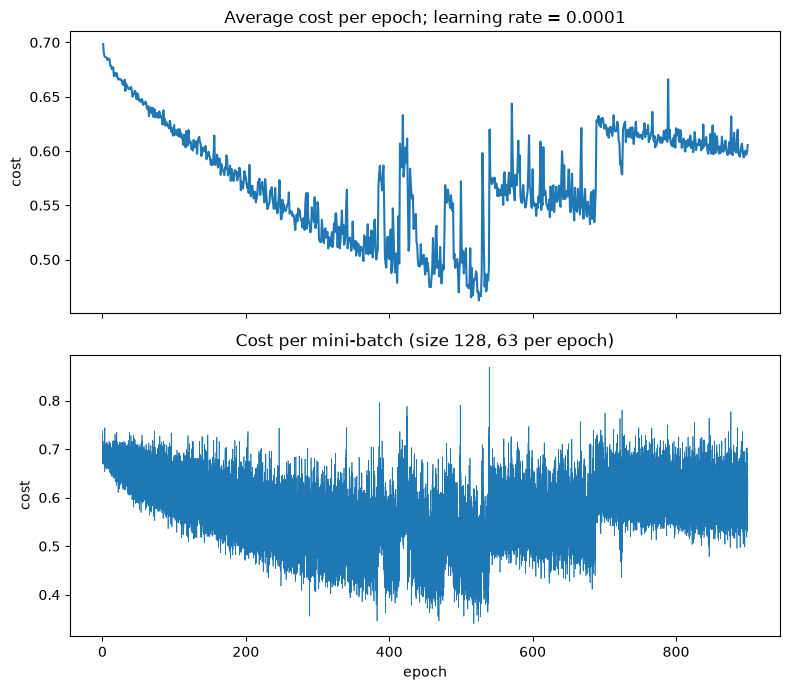

In [19]:
# epoch_costs has one point per epoch, batch_costs one point per mini-batch update.
# Put both on an epoch axis so the noise of each mini-batch lines up with its epoch.
batches_per_epoch = len(batch_costs) // len(epoch_costs)
epochs = np.arange(1, len(epoch_costs) + 1)
batch_steps = np.arange(1, len(batch_costs) + 1) / batches_per_epoch

fig, (ax_epoch, ax_batch) = plt.subplots(2, 1, sharex=True, figsize=(8, 7))

ax_epoch.plot(epochs, epoch_costs)
ax_epoch.set_title(f"Average cost per epoch; learning rate = {learning_rate}")
ax_epoch.set_ylabel("cost")

ax_batch.plot(batch_steps, batch_costs, linewidth=0.5)
ax_batch.set_title(f"Cost per mini-batch (size {mini_batch_size}, {batches_per_epoch} per epoch)")
ax_batch.set_xlabel("epoch")
ax_batch.set_ylabel("cost")

plt.tight_layout()
plt.show()

Deep Neural Network predict it's a dogs picture


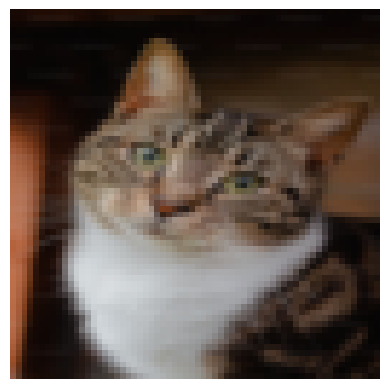

In [29]:
my_image = "cat_focus.png"
image, x_real_data = load_image(my_image)

plt.imshow(image)
plt.axis("off")

deep_prediction = classify(x_real_data, parameter_deep)
print(f"Deep Neural Network predict it's a {get_label(deep_prediction)} picture")